In [63]:
import h5py
import numpy as np
h5py.enable_ipython_completer()

import os
import time

import matplotlib
import matplotlib.pyplot as plt
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


Read the file

In [64]:
print('current working directory:', os.getcwd())
data_dir = os.path.join(os.getcwd(), 'Data')

#Open the H5 file in read mode
file = data_dir + '/' + 'epic_1b_20170131000830_04.h5'
f = h5py.File(file)

current working directory: c:\Users\mathi\OneDrive\Documents\Livet\Msc_geo\4_semester\special_kursus_climate


Check file content

In [65]:

print(list(f))
print(len(list(f)))

['Band317nm', 'Band325nm', 'Band340nm', 'Band388nm', 'Band443nm', 'Band551nm', 'Band680nm', 'Band688nm', 'Band764nm', 'Band780nm']
10


Check content within the groups

In [66]:
list(f['Band443nm'])

['Geolocation', 'Image', 'PixelType']

Check the attributes for the geolocation data

In [67]:
# make table of attributes of the file
# ([("Attribute", "Value")] + list(f['Band443nm']['Geolocation']['Earth'].attrs.items()))

for name, value in f['Band443nm']['Geolocation']['Earth'].attrs.items():
    print(f"{name}: {value}")



apparent_sidereal_time: [8.75555724]
attitude_quaternion_0: [-0.39048]
attitude_quaternion_1: [-0.83524]
attitude_quaternion_2: [-0.38314]
attitude_quaternion_3: [0.05577]
bottom_latitude: [-67.30794271]
bottom_longitude: [13.60107422]
centroid_center_height: [0.]
centroid_center_latitude: [-23.03466797]
centroid_center_longitude: [-173.67919922]
centroid_equatorial_pixel_size: [1549.39818332]
centroid_polar_pixel_size: [1544.20334457]
centroid_x_pixel_offset: [1024.]
centroid_y_pixel_offset: [1024.]
corrected_rotation_x: [-23.035803]
corrected_rotation_y: [172.603938]
corrected_rotation_z: [139.097303]
dscovr_apparent_declination: [-23.03580281]
dscovr_apparent_right_ascension: [-2.75092145]
dscovr_declination: [-23.10483241]
dscovr_ephemeris_x_position: [1072337.9500011]
dscovr_ephemeris_x_velocity: [0.1619]
dscovr_ephemeris_y_position: [-948984.71874905]
dscovr_ephemeris_y_velocity: [0.14050012]
dscovr_ephemeris_z_position: [-610921.16610215]
dscovr_ephemeris_z_velocity: [0.06055]
d

In [68]:

min_lon_attr = f.attrs.get('')
max_lon_attr = f.attrs.get('maximum_longitude')

print(f"--- From Root Attributes ---")
print(f"Minimum Longitude: {min_lon_attr}")
print(f"Maximum Longitude: {max_lon_attr}")

--- From Root Attributes ---
Minimum Longitude: None
Maximum Longitude: [179.97802734]


Look at all the bands within the file

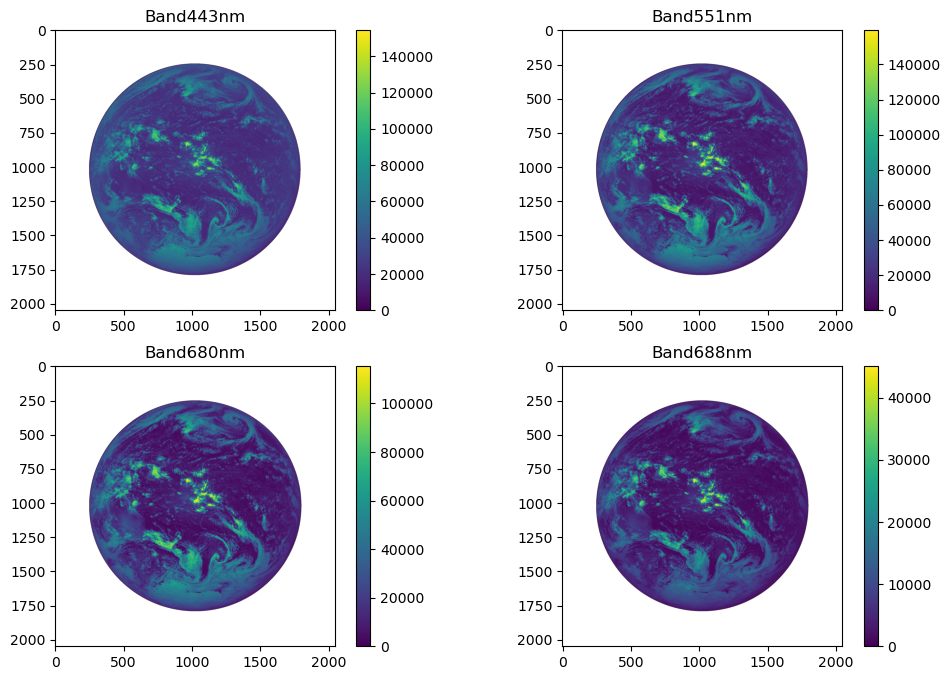

In [69]:
VIS = ['Band443nm', 'Band551nm', 'Band680nm', 'Band688nm']

fig = plt.figure(figsize=(12, 8))
i = 1
for bands in VIS:
    a = fig.add_subplot(2, 2, i)
    img = f[bands]['Image']
    img = np.fliplr(np.rot90(img, -1))
    plt.imshow(img)
    plt.colorbar()
    a.set_title(bands)
    i += 1
    
plt.show()

Extract the center latitude and langitude, the east and west longitudes and top and bottom latitudes

In [70]:
# print the centroid coordinates of the image
print('Centroid Latitude:', f['Band443nm']['Geolocation']['Earth'].attrs['centroid_center_latitude'])
print('Centroid Longitude:', f['Band443nm']['Geolocation']['Earth'].attrs['centroid_center_longitude'])

Centroid Latitude: [-23.03466797]
Centroid Longitude: [-173.67919922]


In [71]:
print('West Longitude:', f['Band443nm']['Geolocation']['Earth'].attrs['west_longitude'])
print('East Longitude:', f['Band443nm']['Geolocation']['Earth'].attrs['east_longitude'])

#print('right Longitude:', f['Band443nm']['Geolocation']['Earth'].attrs['right_longitude'])
print('left Longitude:', f['Band443nm']['Geolocation']['Earth'].attrs['left_longitude'])

West Longitude: [-179.97802734]
East Longitude: [179.97802734]
left Longitude: [98.39355469]


In [72]:
print('North Latitude:', f['Band443nm']['Geolocation']['Earth'].attrs['north_latitude'])
print('South Latitude:', f['Band443nm']['Geolocation']['Earth'].attrs['south_latitude'])

North Latitude: [66.55517578]
South Latitude: [-89.95907948]


### Geolocation Earth grid

Latitude grid shape: (2048, 2048)
Longitude grid shape: (2048, 2048)


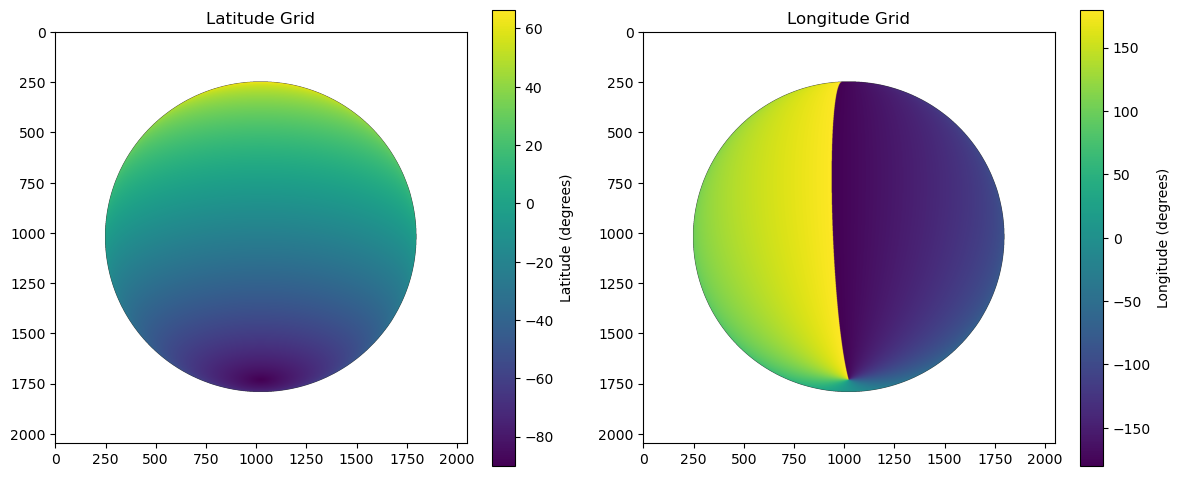

In [73]:
mask_grid = f['Band443nm']['Geolocation']['Earth']['Mask']
mask_grid = np.fliplr(np.rot90(mask_grid, -1))
mask_grid = mask_grid > 0

lat_grid = f['Band443nm']['Geolocation']['Earth']['Latitude']
print('Latitude grid shape:', lat_grid.shape)
lat_grid = np.fliplr(np.rot90(lat_grid, -1))
lat_grid = np.ma.masked_array(lat_grid, mask=~mask_grid)

lon_grid = f['Band443nm']['Geolocation']['Earth']['Longitude']
print('Longitude grid shape:', lon_grid.shape)
lon_grid = np.fliplr(np.rot90(lon_grid, -1))
lon_grid = np.ma.masked_array(lon_grid, mask=~mask_grid)



# show the latitude and longitude grids as subplot
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(lat_grid)
ax[0].set_title('Latitude Grid')
plt.colorbar(ax[0].imshow(lat_grid), ax=ax[0], orientation='vertical', label='Latitude (degrees)', shrink=0.8)
ax[1].imshow(lon_grid)
ax[1].set_title('Longitude Grid')
plt.colorbar(ax[1].imshow(lon_grid), ax=ax[1], orientation='vertical', label='Longitude (degrees)', shrink=0.8)

plt.tight_layout()
plt.show()

### Create mask from grid and apply to image

Mask grid shape: (2048, 2048)


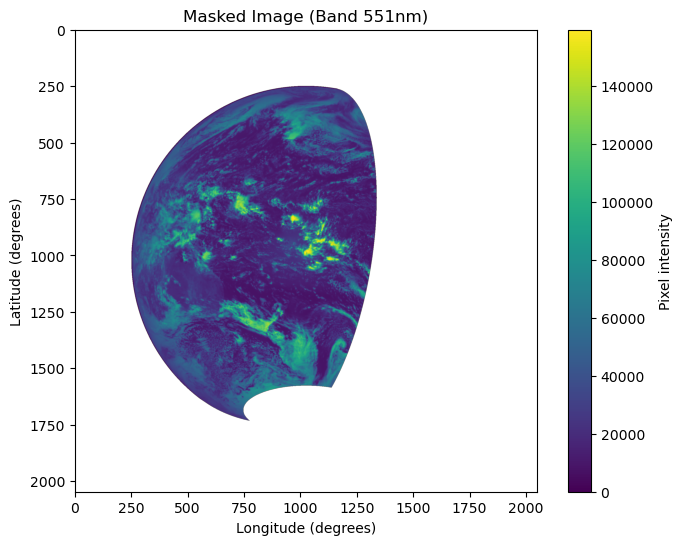

In [74]:
# mask the image using the mask grid

band = 'Band551nm'
image = f[band]['Image']
image = np.fliplr(np.rot90(image, -1))

mask_grid = f[band]['Geolocation']['Earth']['Mask']
print('Mask grid shape:', mask_grid.shape)
mask_grid = np.fliplr(np.rot90(mask_grid, -1))
mask = mask_grid > 0
image_masked = np.ma.masked_array(image, mask=~mask)

# Create mask from grid and apply to image
#mask = (lat_grid >= -90) & (lat_grid <= 90) & (lon_grid >= -80) & (lon_grid <= 54)
mask_atlantic = (lat_grid >= -69) & (lat_grid <= 67) & (lon_grid >= -79) & (lon_grid <= 60)
mask_australasia = (
        (lat_grid >= -69) & (lat_grid <= 67) & 
        (((lon_grid > -180) & (lon_grid <= -150)) | ((lon_grid >= 70) & (lon_grid <= 180)))
        )
# mask_australasia = (
#         (lat_grid >= -69) & (lat_grid <= 67) & 
#         ((lon_grid > -180) & (lon_grid <= -150) | (lon_grid >= 70) & (lon_grid <= 180))
#         )

image_masked = np.ma.masked_array(image, mask=~mask_australasia)


plt.figure(figsize=(8, 6))
plt.imshow(image_masked, cmap='viridis')
plt.colorbar(label='Pixel intensity')
plt.title('Masked Image (Band 551nm)')
plt.xlabel('Longitude (degrees)')
plt.ylabel('Latitude (degrees)')
plt.show()


### calculate albedo for the patch

6.66e-06


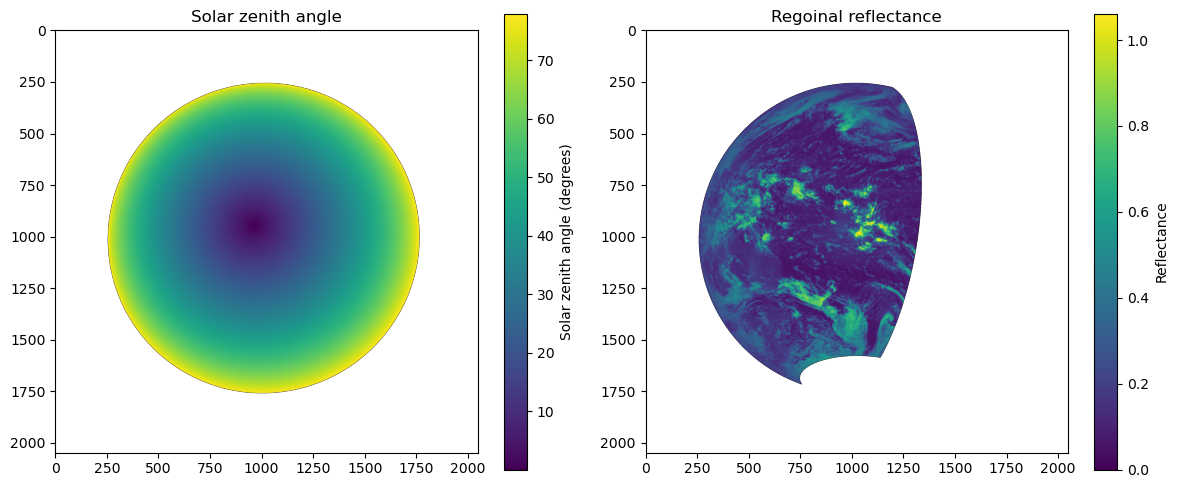

Albedo of masked area = 0.22413916645487625


In [75]:
RCF = {'Band443nm': 8.340e-06,
           'Band551nm': 6.660e-06,
           'Band680nm': 9.300e-06,
           'Band688nm': 2.020e-05}

print(RCF.get(band))
ref_image = image_masked * RCF.get(band)

# mask the reflectance image where sza > 80 degrees
sza = f[band]['Geolocation']['Earth']['SunAngleZenith']
sza = np.fliplr(np.rot90(sza, -1))
sza_mask = (sza > 78)
ref_image = np.ma.masked_array(ref_image, mask=sza_mask)
sza = np.ma.masked_array(sza, mask=sza_mask)

ref_image = np.ma.masked_array(ref_image, mask=sza_mask)


# plt.figure()
# plt.imshow(sza, cmap='viridis')
# plt.colorbar()
# plt.show()

# plt.figure(figsize=(8, 6))
# plt.imshow(ref_image, cmap='viridis')
# plt.colorbar(label='Reflectance')
# plt.title(f'Reflectance of masked image')
# plt.xlabel('Longitude (degrees)')
# plt.ylabel('Latitude (degrees)')
# plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(sza, cmap='viridis')
ax[0].set_title('Solar zenith angle')
plt.colorbar(ax[0].imshow(sza), ax=ax[0], orientation='vertical', label='Solar zenith angle (degrees)', shrink=0.8)
ax[1].imshow(ref_image, cmap='viridis')
ax[1].set_title(f'Regoinal reflectance')
plt.colorbar(ax[1].imshow(ref_image), ax=ax[1], orientation='vertical', label='Reflectance', shrink=0.8)

plt.tight_layout()
plt.show()


mean_albedo = np.mean(ref_image)
print(f'Albedo of masked area = {mean_albedo}')



In [76]:
# find the maximum and minimum values of the reflectance image
max_ref = np.max(ref_image)
min_ref = np.min(ref_image)
print(f'Maximum reflectance = {max_ref}')
print(f'Minimum reflectance = {min_ref}')

# get the albedo of the masked area in the image
albedo = np.mean(ref_image)

# get the lambertian reflectance of the masked area in the image
lambertian_reflectance = np.mean(ref_image)
print(f'Lambertian reflectance = {lambertian_reflectance}')


Maximum reflectance = 1.0616713284375
Minimum reflectance = 0.0
Lambertian reflectance = 0.22413916645487625
